In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Лабораторная работа №2 
### Полиномиальная регрессия. Регуляризация. Кросс-валидация


1. Реализуйте программно восстановление функциональной зависимости методом наименьших квадратов с помощью полиномиальной регрессии. Для этого:
- а. используйте значения параметра M ∈ {0, 1, . . . , 15};
- б. генерируйте выборку двумя способами: в первом случае моделируйте ошибку измерения как равномерно распределённую случайную величину, во втором — как нормально распределённую случайную величину;
- в. генерируйте значения x из заданного интервала случайно в соответствии с равномерным распределением;
- г. в качестве распознаваемых функциональных зависимостей используйте следующие:
y=cos x, y=5x^3 + x^2 + 5, y=x sin x, x ∈ [0, 2π]

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)

M_values = list(range(16))

N = 20
x_min, x_max = 0.0, 2 * np.pi
noise_level = 0.1

In [4]:
functions = {
    r"$y = \cos x$": np.cos,
    r"$y = 5x^3 + x^2 + 5$": lambda x: 5 * x**3 + x**2 + 5,
    r"$y = x \sin x$": lambda x: x * np.sin(x),
}

In [5]:
x_grid = np.linspace(x_min, x_max, 1000)
noise_types = ["u", "n"]


def generate_sample(f, noise_type="u") -> tuple:
    x = rng.uniform(x_min, x_max, N)  # выбокра

    f_grid = f(x_grid)
    sigma = noise_level * (f_grid.max() - f_grid.min())

    if noise_type == "u":
        a = sigma * np.sqrt(3)
        eps = rng.uniform(-a, a, N)
    else:
        eps = rng.normal(0, sigma, N)

    return x, f(x) + eps

In [6]:
# def design_matrix0(x, M):
#     return np.vander(x, M + 1, increasing=True)


def design_matrix(x, M):
    u = (x - (x_min + x_max) / 2) / ((x_max - x_min) / 2)
    return np.vander(u, M + 1, increasing=True)


def fit_polynomial(x, t, M):
    Phi = design_matrix(x, M)
    w, *_ = np.linalg.lstsq(Phi, t, rcond=None)
    return w


def predict(x, w):
    return design_matrix(x, len(w) - 1) @ w

In [7]:
results = {}  # ф-я, шум: выборка, веса и ошибки для всех M

for f_name, f in functions.items():
    for noise_type in noise_types:
        x, t = generate_sample(f, noise_type)
        f_true = f(x_grid)

        weights, train_err, true_err = [], [], []
        for M in M_values:
            w = fit_polynomial(x, t, M)
            weights.append(w)
            train_err.append(np.sqrt(np.mean((predict(x, w) - t) ** 2)))
            true_err.append(np.sqrt(np.mean((predict(x_grid, w) - f_true) ** 2)))

        results[(f_name, noise_type)] = {
            "x": x,
            "t": t,
            "weights": weights,
            "train_err": np.array(train_err),
            "true_err": np.array(true_err),
        }

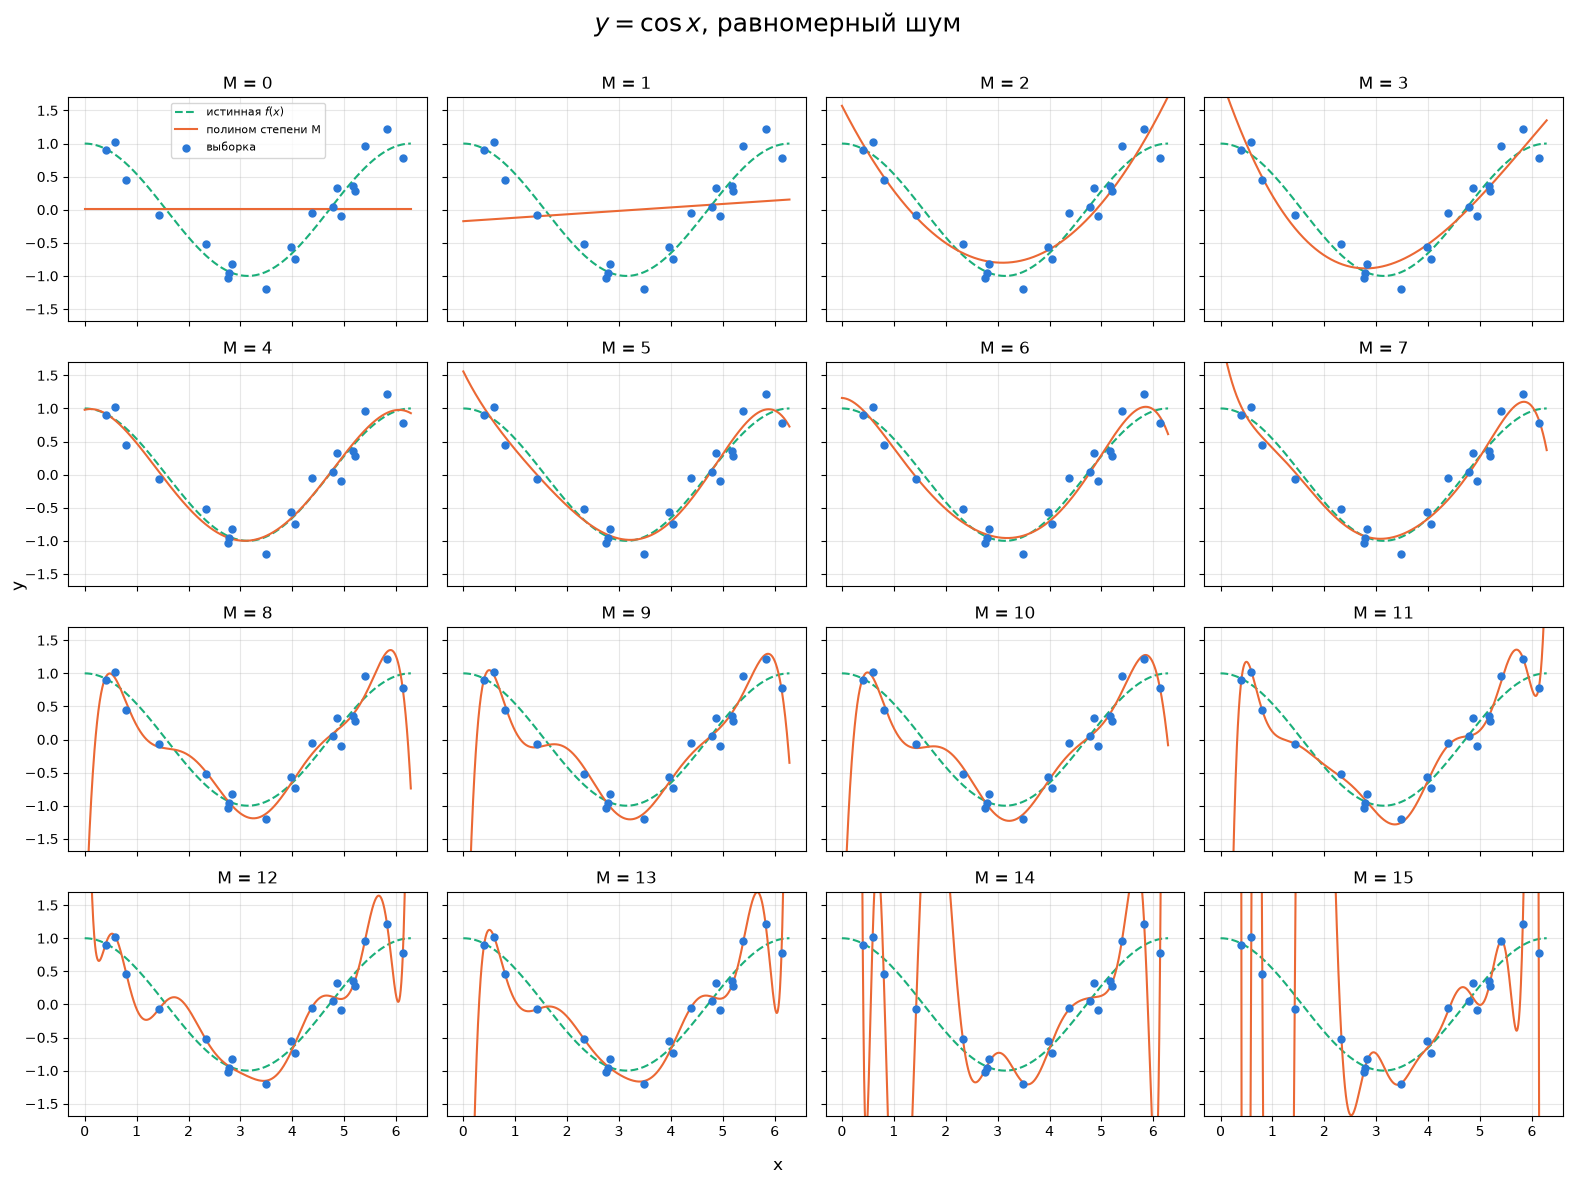

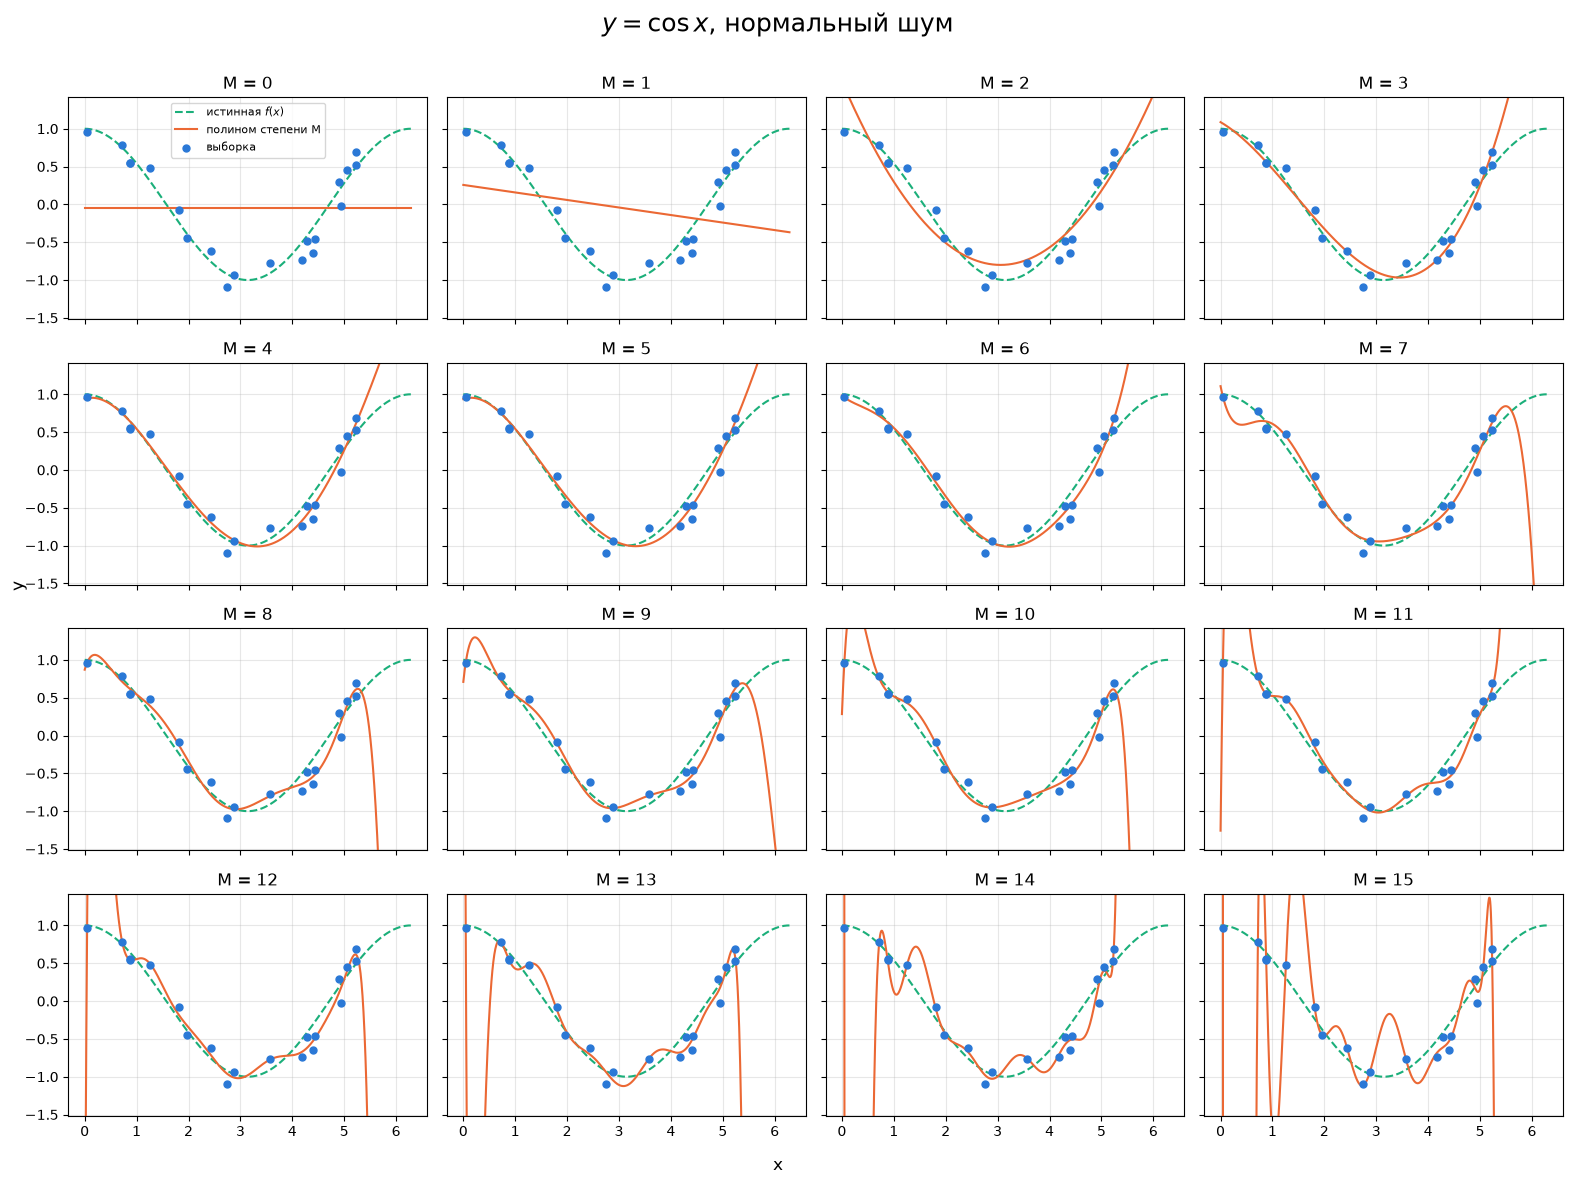

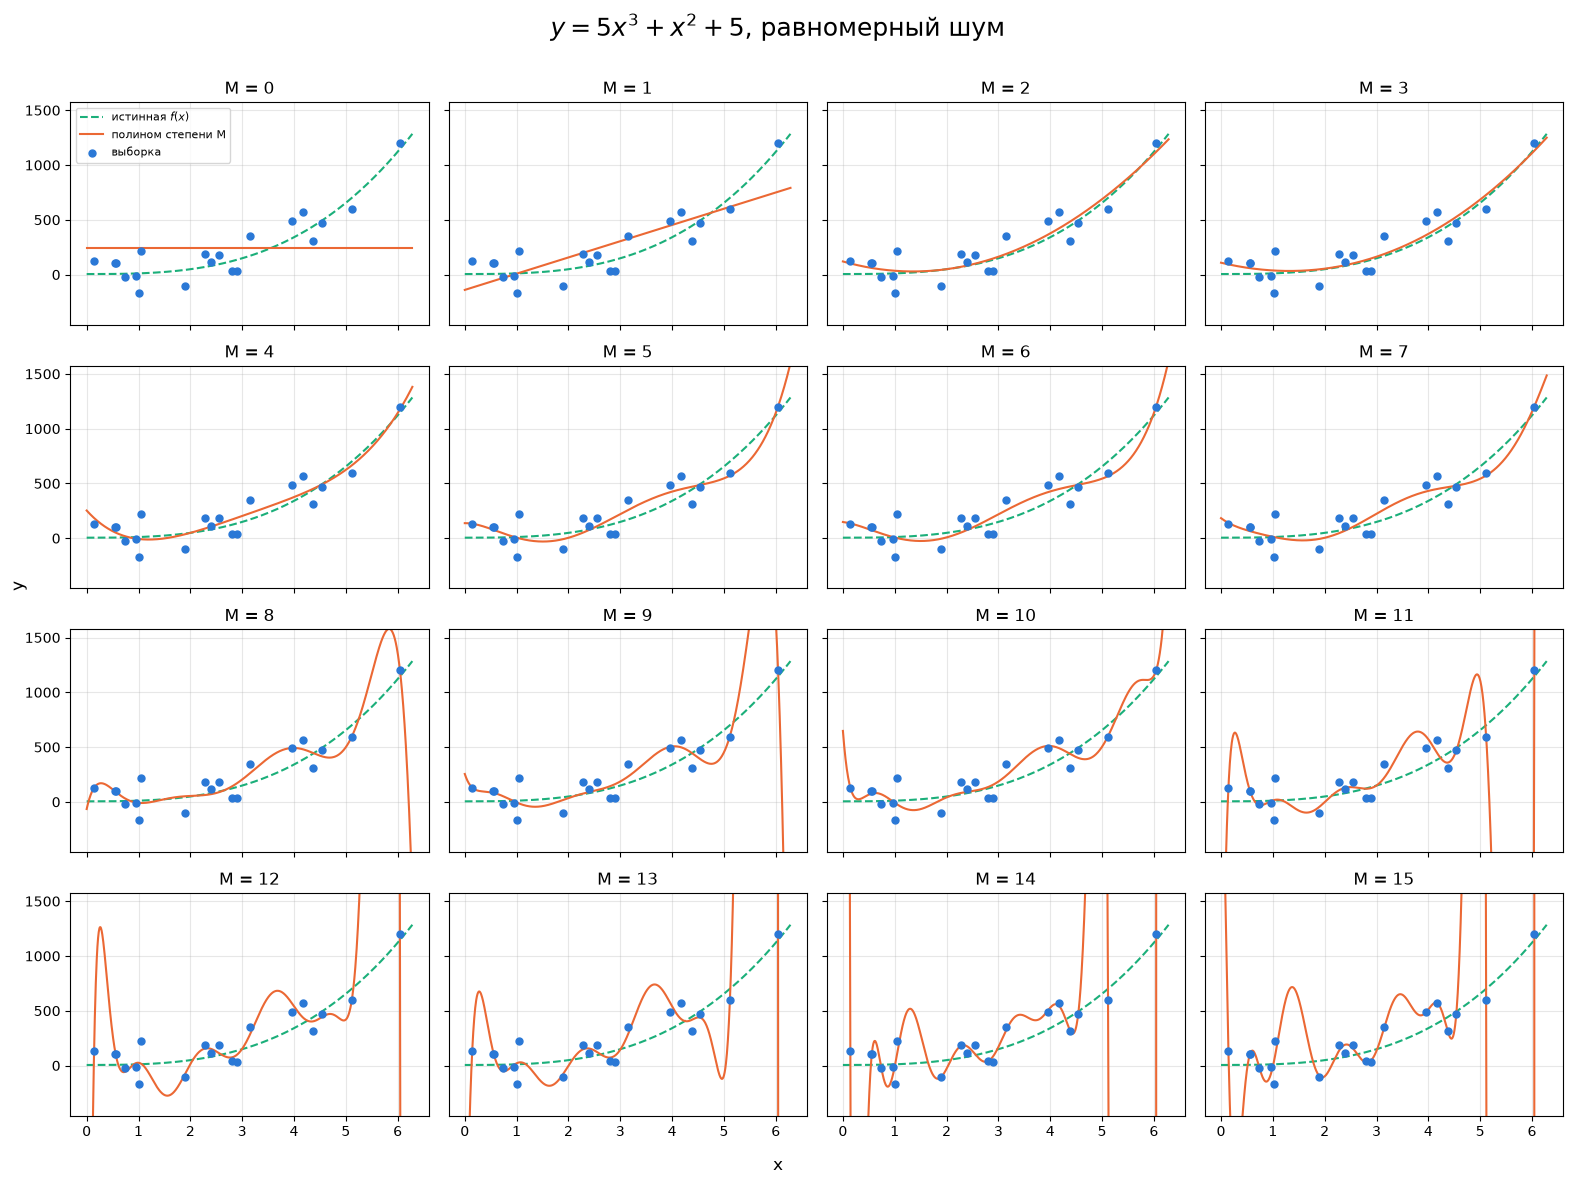

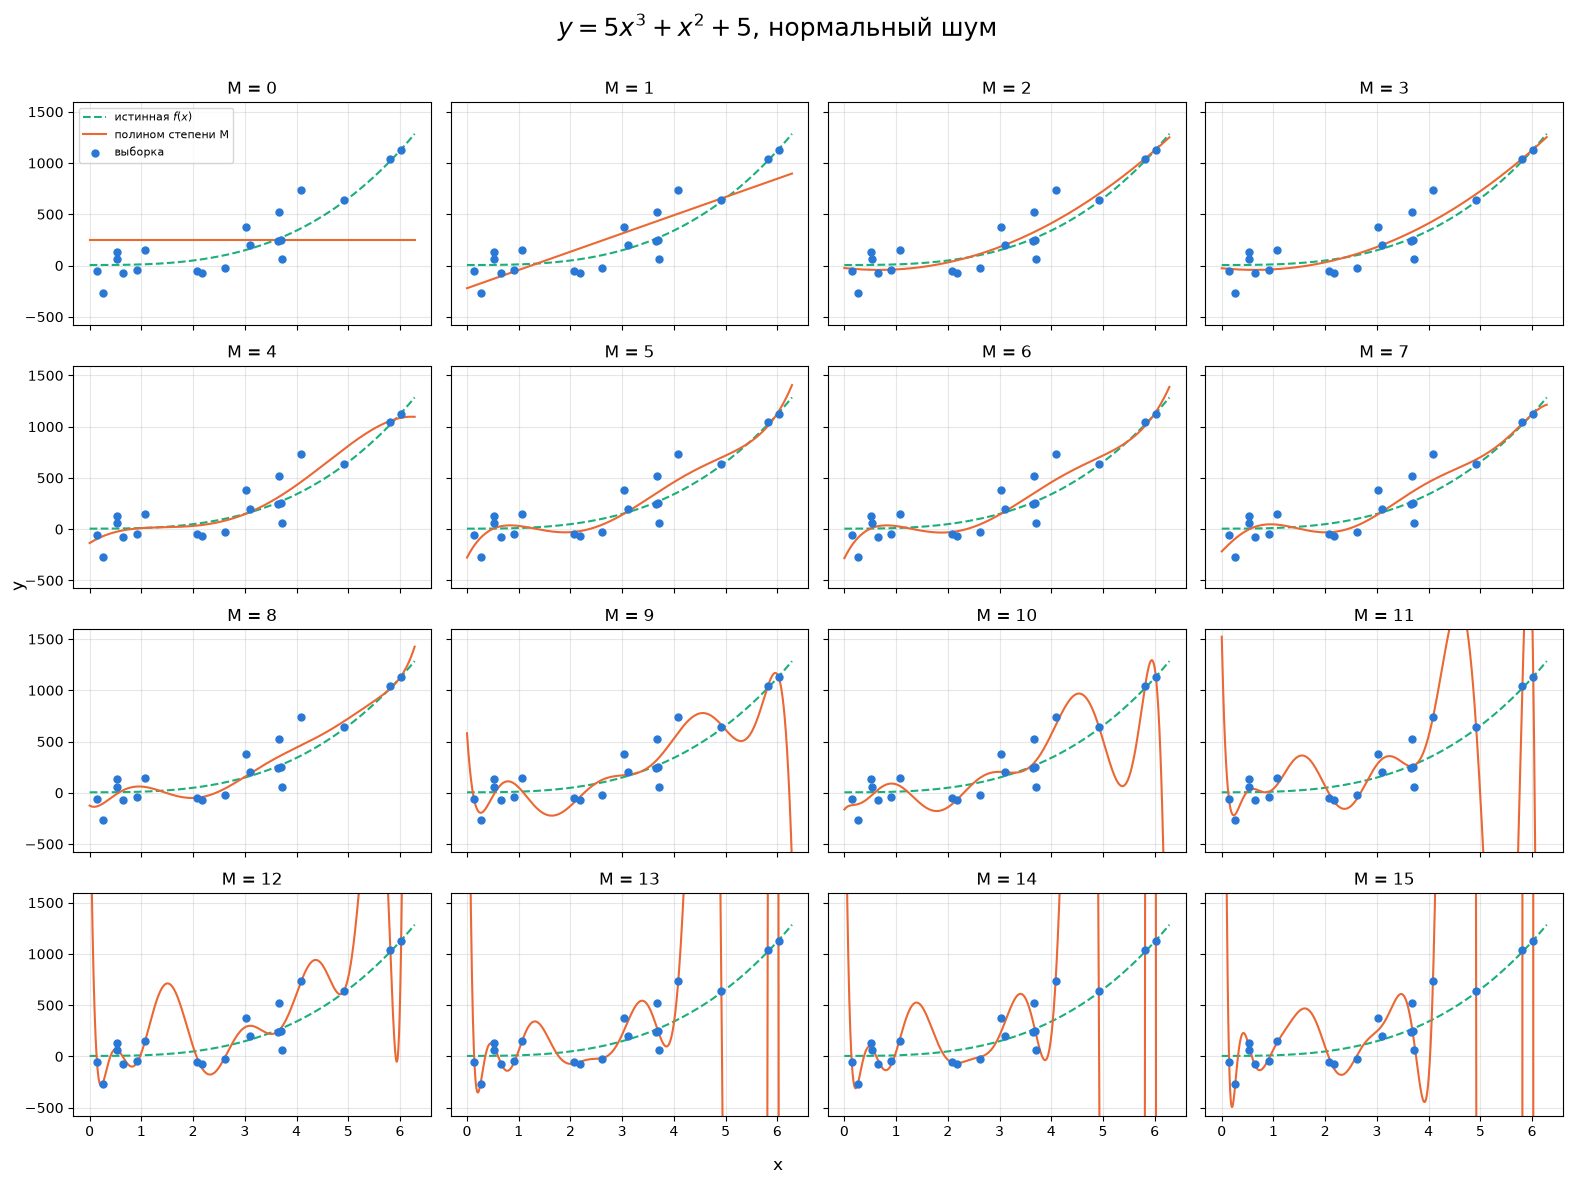

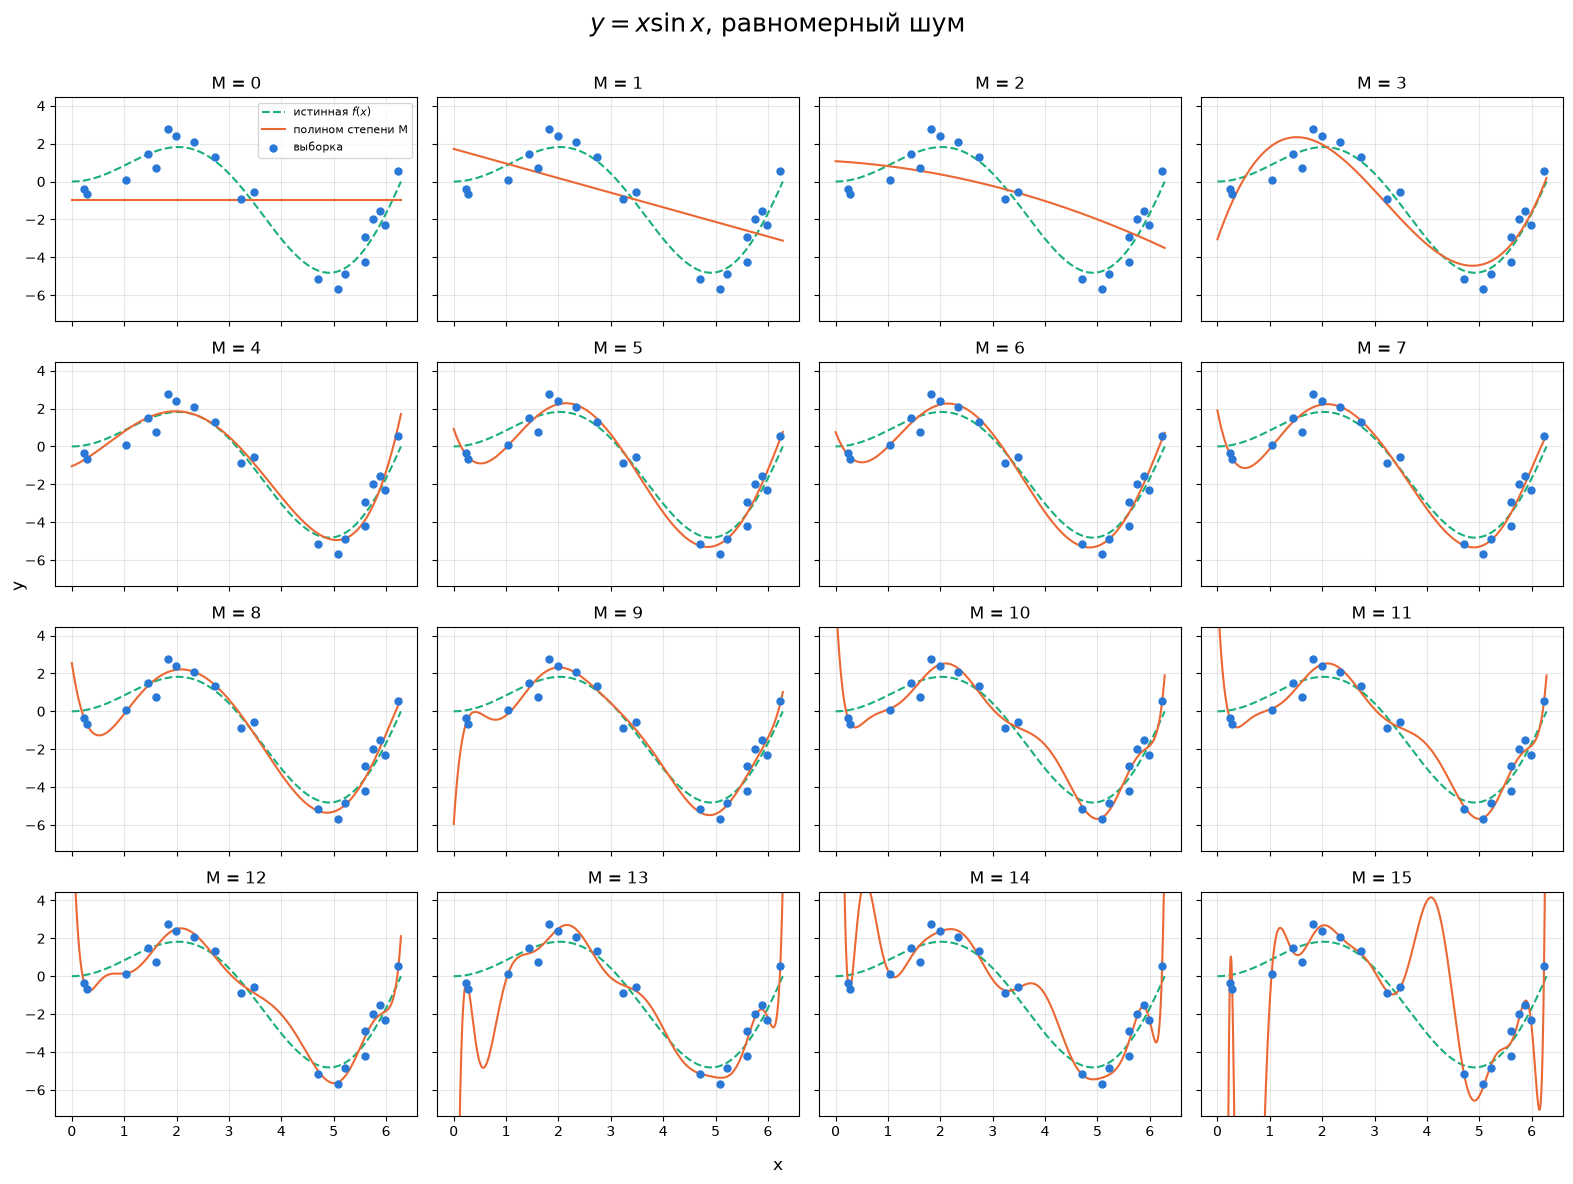

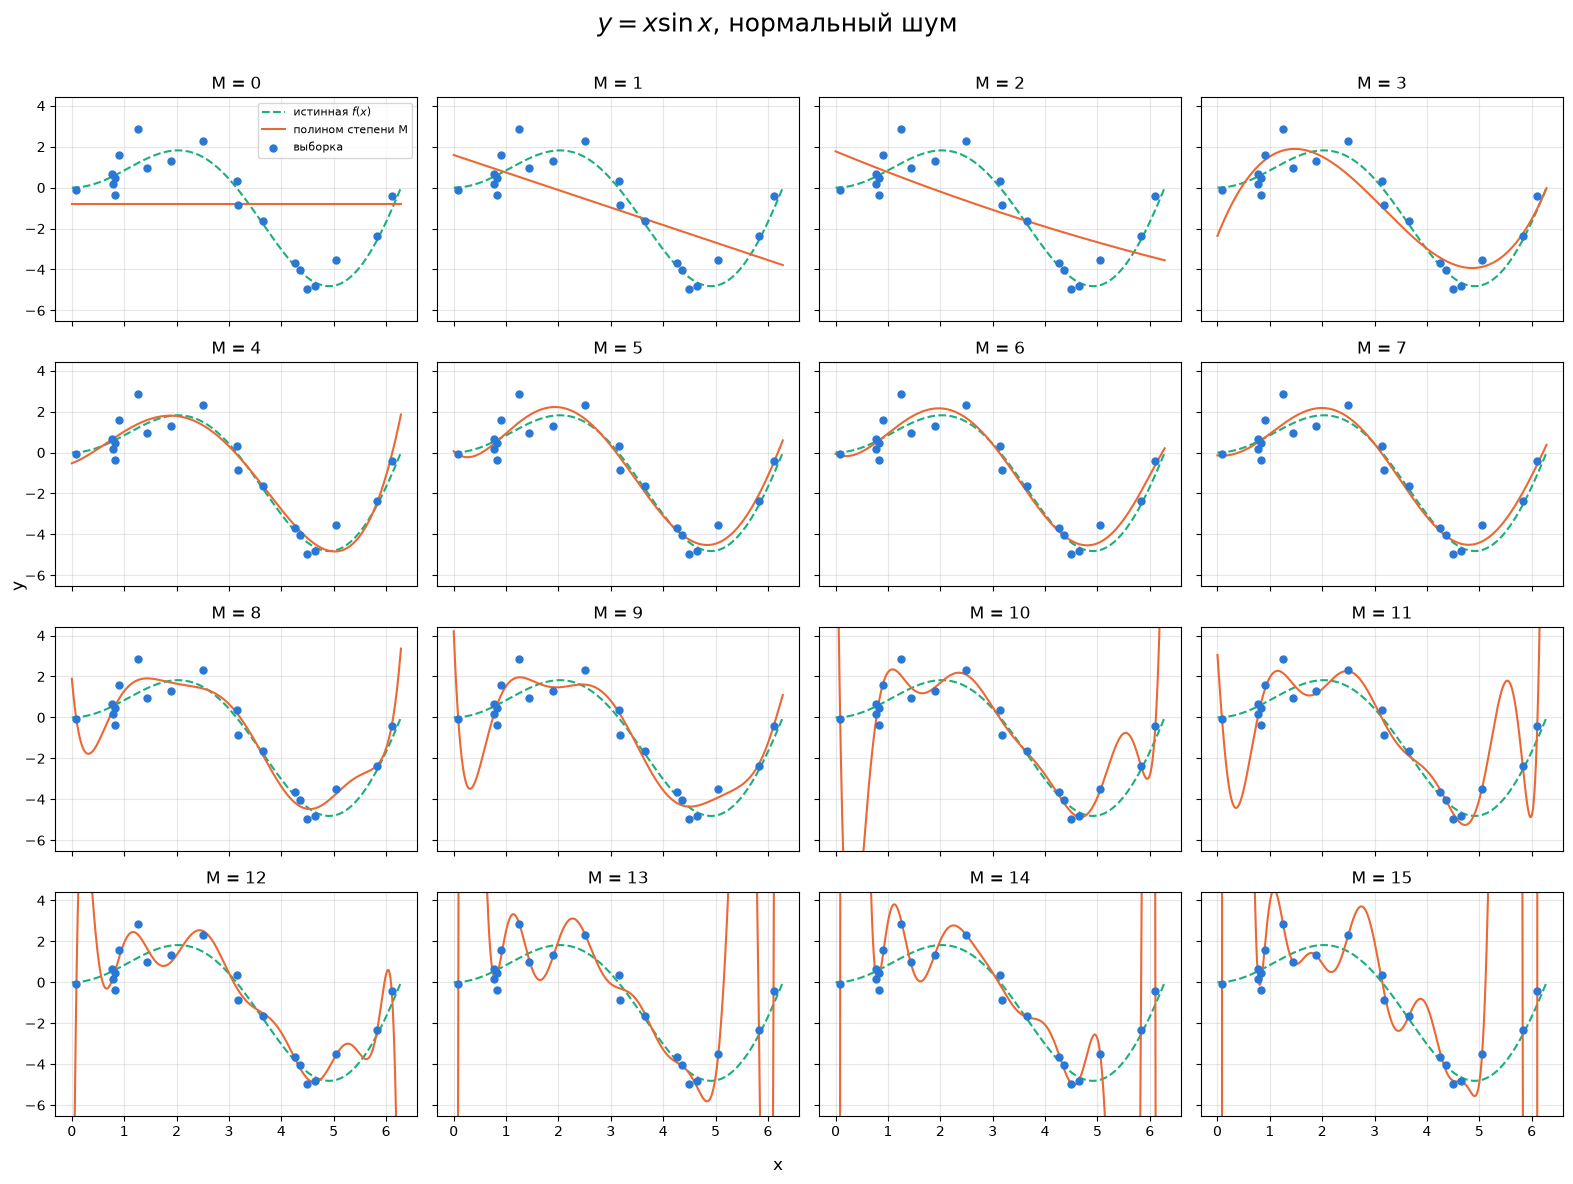

In [8]:
noise_names = {"u": "равномерный шум", "n": "нормальный шум"}

for (f_name, noise_type), res in results.items():
    x, t = res["x"], res["t"]
    f_true = functions[f_name](x_grid)

    # пределы по функции и выборке, с запасом 0.2
    y_lo, y_hi = min(f_true.min(), t.min()), max(f_true.max(), t.max())
    pad = 0.2 * (y_hi - y_lo)

    fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharex=True, sharey=True)
    for M, ax in zip(M_values, axes.flat):
        ax.plot(x_grid, f_true, "--", color="#1baf7a", lw=1.5, label="истинная $f(x)$")
        ax.plot(
            x_grid,
            predict(x_grid, res["weights"][M]),
            "-",
            color="#eb6834",
            lw=1.5,
            label="полином степени M",
        )
        ax.scatter(x, t, s=25, color="#2a78d6", zorder=3, label="выборка")
        ax.set_title(f"M = {M}")
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    fig.supxlabel("x")
    fig.supylabel("y")
    fig.suptitle(f"{f_name}, {noise_names[noise_type]}\n", fontsize=18)
    fig.tight_layout()
    plt.show()

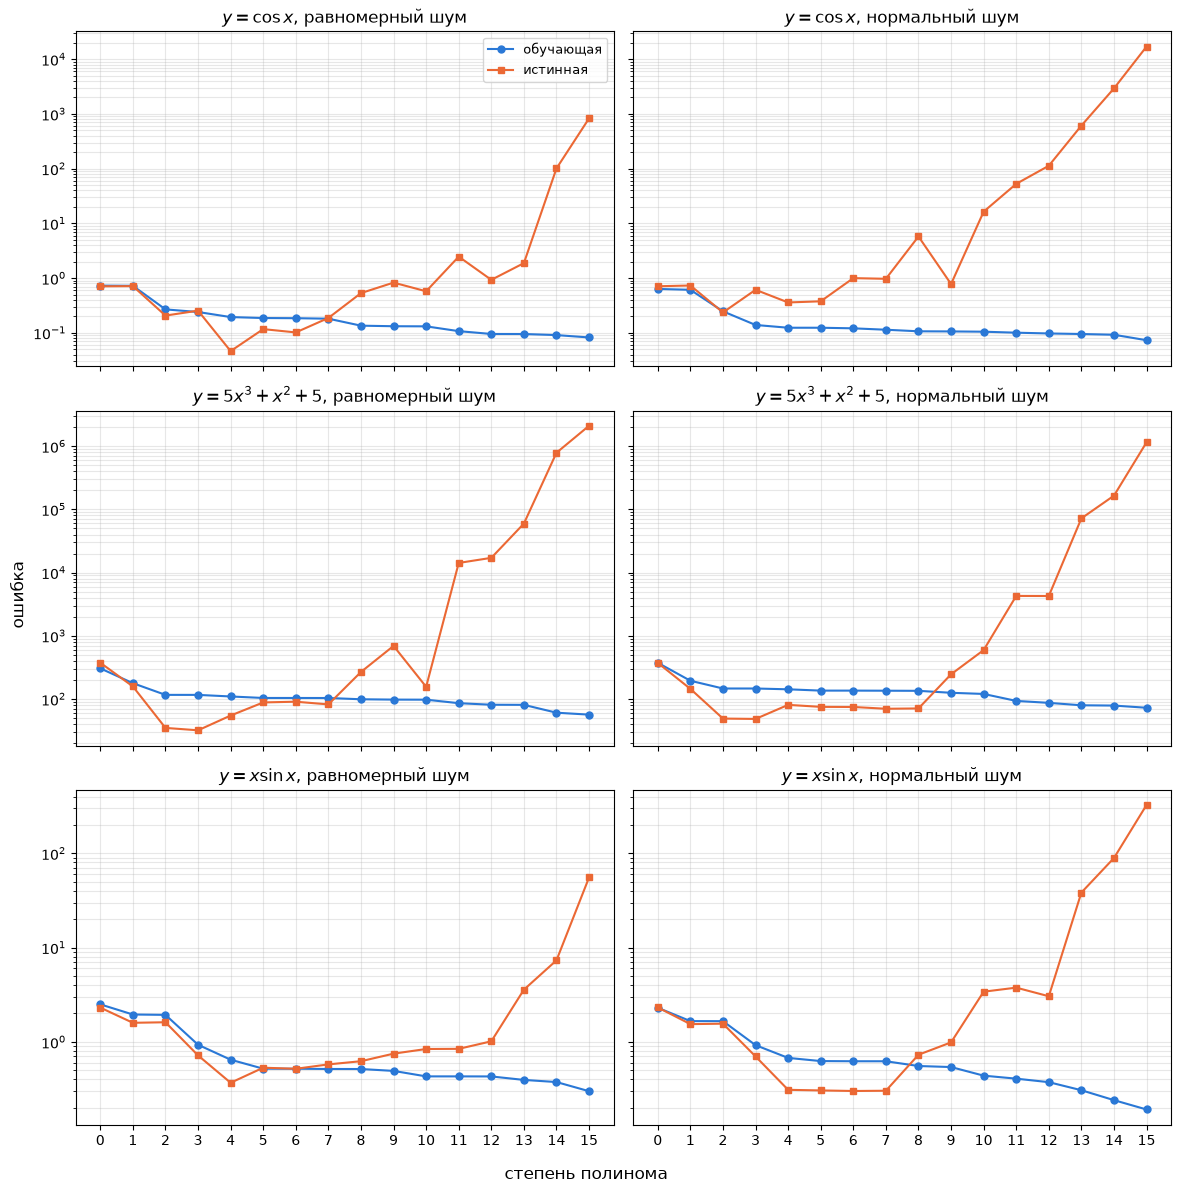

In [9]:
fig, axes = plt.subplots(
    len(functions), len(noise_types), figsize=(12, 12), sharex=True, sharey="row"
)

for i, f_name in enumerate(functions):
    for j, noise_type in enumerate(noise_types):
        res, ax = results[(f_name, noise_type)], axes[i, j]
        ax.plot(
            M_values,
            res["train_err"],
            "o-",
            color="#2a78d6",
            lw=1.5,
            ms=5,
            label="обучающая",
        )
        ax.plot(
            M_values,
            res["true_err"],
            "s-",
            color="#eb6834",
            lw=1.5,
            ms=5,
            label="истинная",
        )
        ax.set_yscale("log")
        ax.set_xticks(M_values)
        ax.set_title(f"{f_name}, {noise_names[noise_type]}")
        ax.grid(alpha=0.3, which="both")

axes[0, 0].legend(fontsize=9)
fig.supxlabel("степень полинома")
fig.supylabel("ошибка")
fig.tight_layout()
plt.show()

2. При условиях, сформулированных в задаче 3, реализуйте программно регуляризацию для полиномиальной регрессии и покажите, что переобучение может быть устранено при некоторых значениях M и λ. Найдите эти значения для выбранных функций и некоторых выборок, полученных для этих функций.

In [10]:
def fit_polynomial_reg(x, t, M, lam):  # L2
    Phi = design_matrix(x, M)
    A = np.vstack([Phi, np.sqrt(lam) * np.eye(M + 1)])
    b = np.concatenate([t, np.zeros(M + 1)])
    w, *_ = np.linalg.lstsq(A, b, rcond=None)
    return w

In [11]:
# λ = 0 (обычный МНК, задача 1) и 10^-12 ... 10^2 с шагом 10^0.5
lambdas = np.concatenate([[0.0], np.logspace(-12, 2, 29)])

reg_results = (
    {}
)  # (функция, тип шума) -> RMS-ошибка относительно f, матрица len(M_values) × len(lambdas)

for (f_name, noise_type), res in results.items():
    x, t = res["x"], res["t"]  # те же выборки, что в задаче 1
    f_true = functions[f_name](x_grid)

    true_err = np.zeros((len(M_values), len(lambdas)))
    for i, M in enumerate(M_values):
        for j, lam in enumerate(lambdas):
            w = fit_polynomial_reg(x, t, M, lam)
            true_err[i, j] = np.sqrt(np.mean((predict(x_grid, w) - f_true) ** 2))

    reg_results[(f_name, noise_type)] = true_err